Remaining classes: [0 1 2 3 4 5 6 7 8 9]
LDA shapes: (45000, 9) (5000, 9)


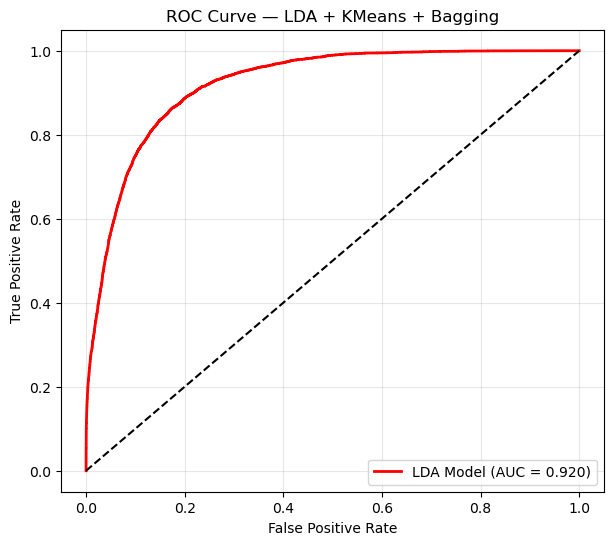

FINAL LDA AUC = 0.9204308244444444


In [25]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.impute import SimpleImputer
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis as LDA
from sklearn.cluster import KMeans
from sklearn.ensemble import BaggingClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import roc_curve, auc
from sklearn.preprocessing import label_binarize
import random

# ================================
# 1. SET SEED
# ================================
seed = 14418269
random.seed(seed)
np.random.seed(seed)

# ================================
# 2. LOAD DATA
# ================================
df = pd.read_csv("musicData.csv")

cols = [
    "popularity", "acousticness", "danceability", "duration_ms",
    "energy", "instrumentalness", "key", "liveness", "loudness",
    "mode", "speechiness", "tempo", "valence", "music_genre"
]

data = df[cols].copy()

# ================================
# 3. ENCODE CATEGORICAL VARIABLES
# ================================
key_map = {
    "C":0, "C#":1, "D":2, "D#":3, "E":4, "F":5,
    "F#":6, "G":7, "G#":8, "A":9, "A#":10, "B":11
}
data["key"] = data["key"].map(key_map)
data["mode"] = data["mode"].map({"Minor":0, "Major":1})
data = data.replace("?", np.nan)

# ================================
# 4. SEPARATE X AND y
# ================================
X = data.drop("music_genre", axis=1)
y = LabelEncoder().fit_transform(data["music_genre"])

# ================================
# 5. REMOVE GENRE 10 (only 5 samples)
# ================================
mask = (y != 10)
X = X[mask]
y = y[mask]

print("Remaining classes:", np.unique(y))

# ================================
# 6. TRAIN / TEST SPLIT (500 per genre)
# ================================
train_idx, test_idx = [], []

for g in np.unique(y):
    idx = np.where(y == g)[0]
    np.random.shuffle(idx)
    test_idx.extend(idx[:500])
    train_idx.extend(idx[500:])

train_idx = np.array(train_idx)
test_idx = np.array(test_idx)

X_train = X.iloc[train_idx]
X_test = X.iloc[test_idx]
y_train = y[train_idx]
y_test = y[test_idx]

# ================================
# 7. HANDLE MISSING VALUES
# ================================
imp = SimpleImputer(strategy="median")
X_train_imp = imp.fit_transform(X_train)
X_test_imp = imp.transform(X_test)

# ================================
# 8. SCALE FEATURES
# ================================
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_imp)
X_test_scaled = scaler.transform(X_test_imp)

lda = LDA(n_components=9)
X_train_lda = lda.fit_transform(X_train_scaled, y_train)
X_test_lda = lda.transform(X_test_scaled)

print("LDA shapes:", X_train_lda.shape, X_test_lda.shape)

# ================================
# 10. K-MEANS ON LDA SPACE
# ================================
kmeans = KMeans(n_clusters=10, random_state=seed, n_init=10)
cluster_train = kmeans.fit_predict(X_train_lda)
cluster_test = kmeans.predict(X_test_lda)

# Add cluster ID as a feature
X_train_final = np.hstack([X_train_lda, cluster_train.reshape(-1,1)])
X_test_final = np.hstack([X_test_lda, cluster_test.reshape(-1,1)])

# ================================
# 11. BAGGING CLASSIFIER
# ================================
tree = DecisionTreeClassifier(max_depth=10, random_state=seed)

bag = BaggingClassifier(
    estimator=tree,
    n_estimators=50,
    max_samples=0.8,
    bootstrap=True,
    random_state=seed,
    n_jobs=-1
)

bag.fit(X_train_final, y_train)

# ================================
# 12. ROC + AUC
# ================================
classes = np.unique(y_train)
y_test_bin = label_binarize(y_test, classes=classes)

probs = bag.predict_proba(X_test_final)

fpr, tpr, _ = roc_curve(y_test_bin.ravel(), probs.ravel())
auc_lda = auc(fpr, tpr)

plt.figure(figsize=(7,6))
plt.plot(fpr, tpr, lw=2, color="red",
         label=f"LDA Model (AUC = {auc_lda:.3f})")
plt.plot([0,1], [0,1], 'k--')
plt.title("ROC Curve — LDA + KMeans + Bagging")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

print("FINAL LDA AUC =", auc_lda)



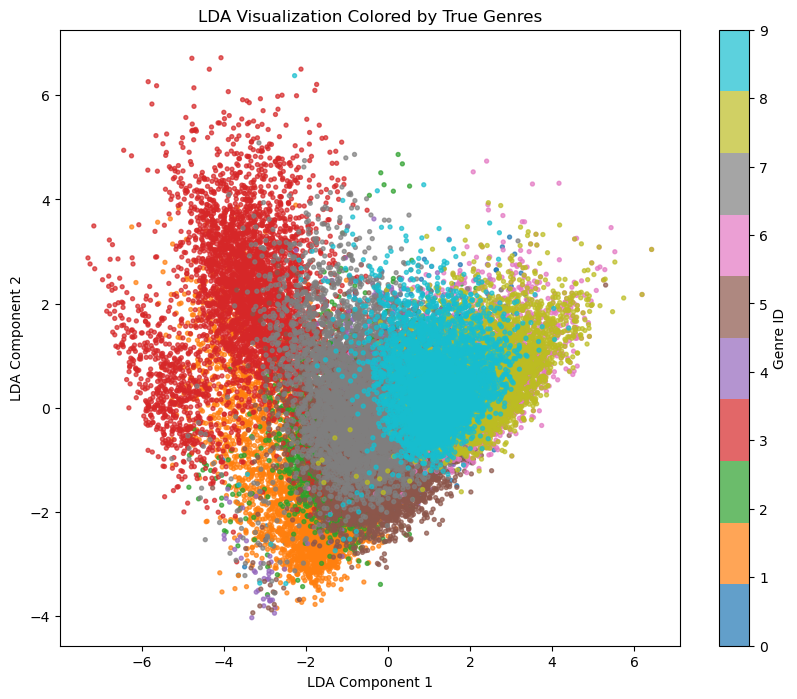

In [26]:
plt.figure(figsize=(10,8))
plt.scatter(
    X_train_lda[:,0],
    X_train_lda[:,1],
    c=y_train,
    cmap="tab10",
    s=8,
    alpha=0.7
)
plt.title("LDA Visualization Colored by True Genres")
plt.xlabel("LDA Component 1")
plt.ylabel("LDA Component 2")
plt.colorbar(label="Genre ID")
plt.show()


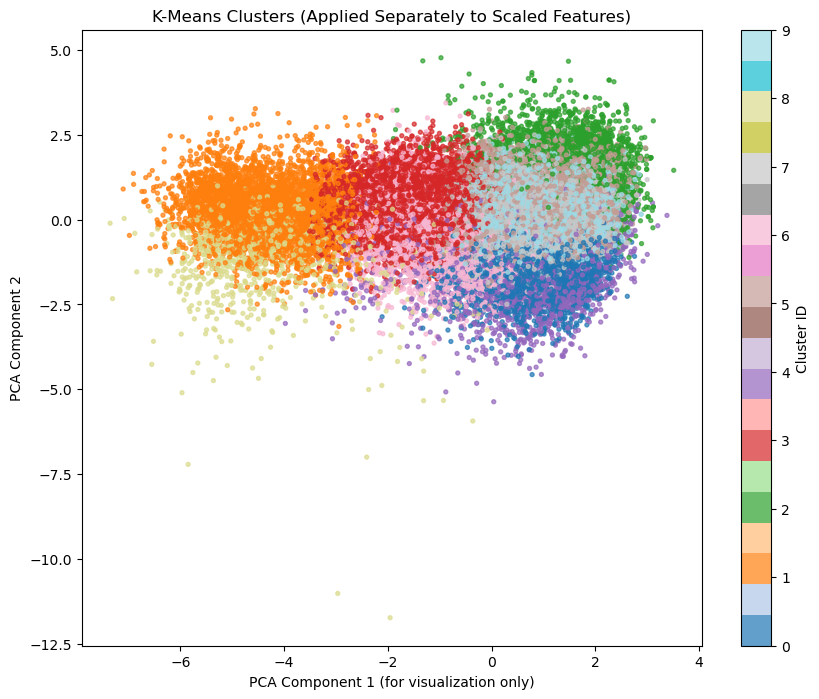

In [28]:
# Run K-Means on the SCALED ORIGINAL TRAIN FEATURES
kmeans_sep = KMeans(n_clusters=10, random_state=seed, n_init=10)
cluster_sep = kmeans_sep.fit_predict(X_train_scaled)

# Visualize with PCA ONLY FOR PLOT (not for model)
from sklearn.decomposition import PCA
pca_plot = PCA(n_components=2)
X_plot = pca_plot.fit_transform(X_train_scaled)

plt.figure(figsize=(10,8))
plt.scatter(
    X_plot[:,0],
    X_plot[:,1],
    c=cluster_sep,
    cmap="tab20",
    s=8,
    alpha=0.7
)
plt.title("K-Means Clusters (Applied Separately to Scaled Features)")
plt.xlabel("PCA Component 1 (for visualization only)")
plt.ylabel("PCA Component 2")
plt.colorbar(label="Cluster ID")
plt.show()


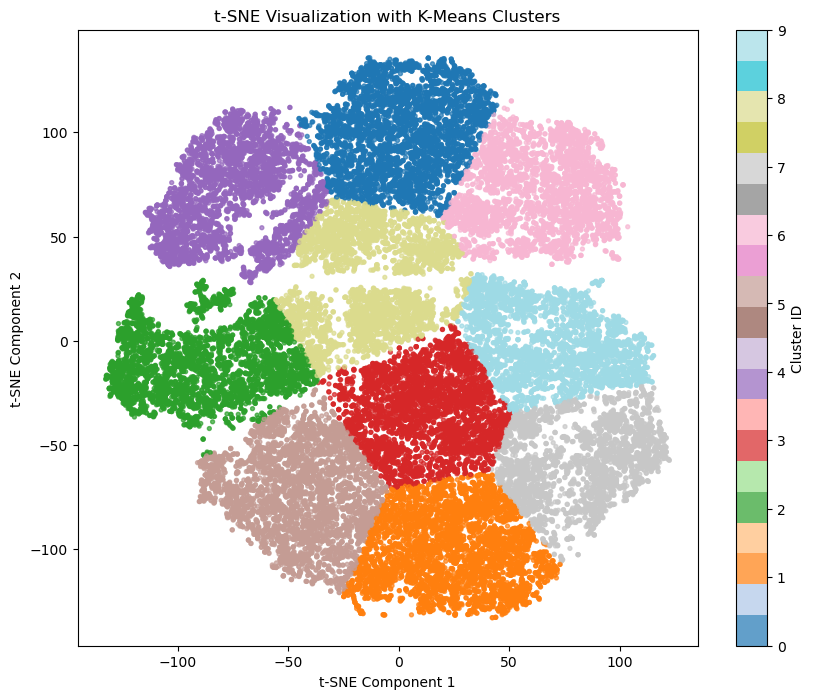

In [31]:
from sklearn.manifold import TSNE
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

# Run t-SNE ONLY for visualization
tsne_vis = TSNE(
    n_components=2,
    perplexity=30,
    learning_rate='auto',
    init='pca',
    random_state=seed,
    max_iter=1500
)

X_train_tsne = tsne_vis.fit_transform(X_train_scaled)

# K-Means on t-SNE output
kmeans_tsne = KMeans(n_clusters=10, random_state=seed, n_init=10)
clusters_tsne = kmeans_tsne.fit_predict(X_train_tsne)

# Plot t-SNE clusters
plt.figure(figsize=(10,8))
plt.scatter(
    X_train_tsne[:,0],
    X_train_tsne[:,1],
    c=clusters_tsne,
    cmap="tab20",
    s=8,
    alpha=0.7
)
plt.title("t-SNE Visualization with K-Means Clusters")
plt.xlabel("t-SNE Component 1")
plt.ylabel("t-SNE Component 2")
plt.colorbar(label="Cluster ID")
plt.show()





In [33]:
import numpy as np
from scipy.spatial.distance import cdist
import pandas as pd

# Compute centroids for each genre in LDA space
centroids = []
labels = np.unique(y_train)

for g in labels:
    centroid = X_train_lda[y_train == g].mean(axis=0)
    centroids.append(centroid)

centroids = np.vstack(centroids)

# Compute pairwise Euclidean distances between centroids
distance_matrix = cdist(centroids, centroids, metric='euclidean')

# Convert to a clean DataFrame for printing
distance_df = pd.DataFrame(
    distance_matrix,
    index=[f"Genre {g}" for g in labels],
    columns=[f"Genre {g}" for g in labels]
)

print("Pairwise Distances Between Genre Centroids (LDA Space):")
print(distance_df.round(3))


Pairwise Distances Between Genre Centroids (LDA Space):
         Genre 0  Genre 1  Genre 2  Genre 3  Genre 4  Genre 5  Genre 6  \
Genre 0    0.000    2.888    1.970    4.440    1.101    1.938    2.127   
Genre 1    2.888    0.000    1.638    3.488    2.644    2.160    4.459   
Genre 2    1.970    1.638    0.000    3.520    1.433    2.189    3.555   
Genre 3    4.440    3.488    3.520    0.000    4.288    4.208    5.639   
Genre 4    1.101    2.644    1.433    4.288    0.000    2.246    2.721   
Genre 5    1.938    2.160    2.189    4.208    2.246    0.000    2.940   
Genre 6    2.127    4.459    3.555    5.639    2.721    2.940    0.000   
Genre 7    1.974    2.267    1.549    3.255    1.822    1.900    3.068   
Genre 8    1.996    4.501    3.569    5.653    2.638    2.975    0.365   
Genre 9    1.179    3.824    2.677    4.846    1.563    2.883    2.369   

         Genre 7  Genre 8  Genre 9  
Genre 0    1.974    1.996    1.179  
Genre 1    2.267    4.501    3.824  
Genre 2    1.549  